# Bab 4 - Pengenalan Pembelajaran Saraf: Gradient Descent

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Bab 3 hanya membuat prediksi. Bab 4 menambahkan langkah **compare (bandingkan)** dan **learn (belajar)**, sehingga jaringan dapat melatih dirinya sendiri.

1. **Compare (Bandingkan):** ukur error dari suatu prediksi. Buku ini menggunakan **mean squared error** untuk satu contoh: `error = (pred - goal)^2`.
2. **Hot and cold learning:** strategi pembelajaran paling sederhana - coba geser bobot ke atas dan ke bawah dan pertahankan mana yang memberikan error lebih rendah. Strategi ini bekerja tetapi lambat dan tidak presisi.
3. **Gradient descent:** gunakan **turunan (derivatif)** dari error terhadap bobot untuk mengetahui *arah dan jumlah* penyesuaian sekaligus dalam satu langkah.
4. Aturan pembaruan `weight = weight - alpha * (pred - goal) * input`, di mana `alpha` adalah **learning rate**.
5. Apa yang **bisa salah**: learning rate yang terlalu besar membuat pelatihan **divergen (meledak)**.
6. Intuition untuk "mangkuk" error: bobot yang meminimalkan squared error berada di dasar kurva berbentuk U (konveks), dan gradient descent meluncur ke bawah (*downhill*).

## Teori secara mendalam

### Error dan mengapa kita menguadratkannya
`error = (pred - goal)^2`. Menguadratkan (a) membuat setiap error bernilai positif sehingga kesalahan di atas dan di bawah target tidak saling menghapuskan,
(b) membuat kesalahan besar jauh lebih mahal daripada kesalahan kecil, dan (c) memberikan kurva mulus yang kemiringannya mengecil saat kita mendekati target, membuat pembelajaran menjadi stabil.

### Hot and cold learning
Coba `weight + step` dan `weight - step`, hitung error untuk masing-masing, dan berpindah ke arah yang memberikan error lebih kecil.
Kelemahan: memerlukan beberapa prediksi per pembaruan, dan ukuran langkah bersifat tetap sehingga dapat melampaui batas (*overshoot*) dan tidak pernah mendarat secara tepat.

### Gradient descent
Error adalah fungsi dari bobot: `error(w) = (x*w - goal)^2`. **Turunannya** (kemiringan/slope) memberi tahu arah mana yang menanjak dan seberapa curam:

* `d error / d weight = 2 * (pred - goal) * input`. Faktor 2 dihilangkan dalam buku ini dan diserap ke dalam `alpha`.
* `delta = pred - goal` adalah "seberapa besar misprediksi node"; `weight_delta = delta * input` adalah "seberapa besar bobot ini berkontribusi pada misprediksi tersebut" (diskalakan oleh input, sehingga input yang lebih kuat memiliki efek lebih besar).
* **Tanda (sign)** dari `weight_delta` memberikan arah, **besaran (magnitude)** memberikan jumlahnya. Kurangi `alpha * weight_delta` dari bobot untuk turun ke bawah.

### Learning rate
`alpha` menskalakan ukuran langkah. Terlalu kecil = pembelajaran lambat. Terlalu besar = setiap langkah melampaui batas minimum lebih dari yang diperbaiki, error membesar, dan bobot meledak (divergensi). Dalam praktiknya `alpha` ditemukan melalui eksperimen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Compare (Bandingkan): satu prediksi dan error-nya

In [2]:
knob_weight = 0.5
inp = 0.5
goal_pred = 0.8

pred = inp * knob_weight
error = (pred - goal_pred) ** 2
print('prediction:', pred, ' error:', error)

prediction: 0.25  error: 0.30250000000000005


## 2. Hot and cold learning

In [3]:
weight = 0.5
goal_pred = 0.8
inp = 0.5
step_amount = 0.001

errors_hc = []
for iteration in range(1101):
    pred = inp * weight
    error = (pred - goal_pred) ** 2
    errors_hc.append(error)
    if iteration % 200 == 0:
        print(f'iter {iteration:4d}  Error: {error:.6f}  Prediction: {pred:.4f}')

    up_pred = inp * (weight + step_amount)
    up_error = (goal_pred - up_pred) ** 2
    down_pred = inp * (weight - step_amount)
    down_error = (goal_pred - down_pred) ** 2

    if down_error < up_error:
        weight -= step_amount
    if down_error > up_error:
        weight += step_amount

iter    0  Error: 0.302500  Prediction: 0.2500
iter  200  Error: 0.202500  Prediction: 0.3500
iter  400  Error: 0.122500  Prediction: 0.4500
iter  600  Error: 0.062500  Prediction: 0.5500
iter  800  Error: 0.022500  Prediction: 0.6500
iter 1000  Error: 0.002500  Prediction: 0.7500


Pembelajaran konvergen, tetapi lambat: membutuhkan lebih dari seribu iterasi karena setiap pembaruan adalah langkah kecil bernilai tetap 0.001 dan membutuhkan dua prediksi ekstra per pembaruan.

## 3. Gradient descent

In [4]:
weight, goal_pred, inp = 0.0, 0.8, 1.1
errors_gd = []
for iteration in range(20):
    pred = inp * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred
    weight_delta = delta * inp
    weight = weight - weight_delta
    errors_gd.append(error)
    print(f'iter {iteration:2d}  Error: {error:.6f}  Prediction: {pred:.4f}')

iter  0  Error: 0.640000  Prediction: 0.0000
iter  1  Error: 0.028224  Prediction: 0.9680
iter  2  Error: 0.001245  Prediction: 0.7647
iter  3  Error: 0.000055  Prediction: 0.8074
iter  4  Error: 0.000002  Prediction: 0.7984
iter  5  Error: 0.000000  Prediction: 0.8003
iter  6  Error: 0.000000  Prediction: 0.7999
iter  7  Error: 0.000000  Prediction: 0.8000
iter  8  Error: 0.000000  Prediction: 0.8000
iter  9  Error: 0.000000  Prediction: 0.8000
iter 10  Error: 0.000000  Prediction: 0.8000
iter 11  Error: 0.000000  Prediction: 0.8000
iter 12  Error: 0.000000  Prediction: 0.8000
iter 13  Error: 0.000000  Prediction: 0.8000
iter 14  Error: 0.000000  Prediction: 0.8000
iter 15  Error: 0.000000  Prediction: 0.8000
iter 16  Error: 0.000000  Prediction: 0.8000
iter 17  Error: 0.000000  Prediction: 0.8000
iter 18  Error: 0.000000  Prediction: 0.8000
iter 19  Error: 0.000000  Prediction: 0.8000


Perhatikan bahwa langkah pertama berukuran besar (kemiringannya curam) dan sedikit melampaui target (0.968 vs 0.8); langkah-langkah berikutnya mengecil secara otomatis seiring prediksi mendekati target, dan error Pada dasarnya menjadi nol setelah sekitar 5 iterasi berbanding lebih dari 1000 iterasi untuk hot and cold learning. Ukuran langkah yang menyesuaikan diri secara otomatis ini adalah keunggulan utama dibandingkan hot and cold learning.

## 4. Kurva error dan efek dari learning rate (alpha)

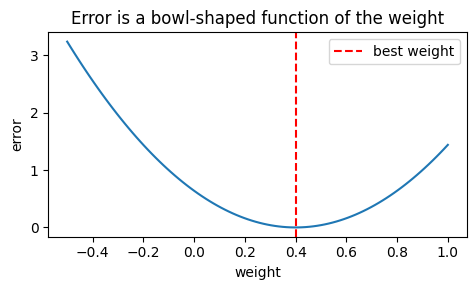

In [5]:
inp, goal_pred = 2.0, 0.8
ws = np.linspace(-0.5, 1.0, 100)
plt.figure(figsize=(5, 3))
plt.plot(ws, (inp * ws - goal_pred) ** 2)
plt.axvline(goal_pred / inp, color='red', ls='--', label='best weight')
plt.xlabel('weight'); plt.ylabel('error'); plt.title('Error is a bowl-shaped function of the weight')
plt.legend(); plt.tight_layout(); plt.show()

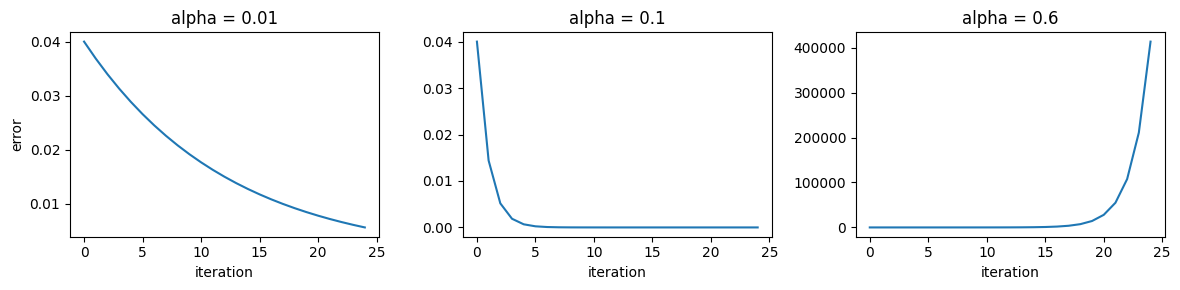

In [6]:
def train(alpha, iterations=25, inp=2.0, goal_pred=0.8, weight=0.5):
    errs = []
    for _ in range(iterations):
        pred = inp * weight
        errs.append((pred - goal_pred) ** 2)
        weight -= alpha * (pred - goal_pred) * inp
    return errs

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, alpha in zip(axes, [0.01, 0.1, 0.6]):
    ax.plot(train(alpha)); ax.set_title(f'alpha = {alpha}'); ax.set_xlabel('iteration')
axes[0].set_ylabel('error')
plt.tight_layout(); plt.show()

Dengan `alpha = 0.01` pembelajaran berjalan lambat, `alpha = 0.1` konvergen secara mulus, dan `alpha = 0.6` terlalu besar: setiap pembaruan melampaui batas minimum secara berlebihan sehingga error membesar (divergensi). Input bernilai 2, sehingga setiap pembaruan mengalikan sisa error dengan `1 - alpha * input^2` (= `1 - 4 * alpha`): bobot konvergen secara mulus ketika `alpha * input^2 < 1`, berosilasi tetapi masih konvergen ketika berada di antara 1 dan 2, dan divergen ketika berada di atas 2, yang terjadi pada `alpha = 0.6`.

## Poin-poin kunci
* Pembelajaran membutuhkan ukuran error; mean squared error digunakan di seluruh buku.
* Turunan memberi tahu kita arah dan ukuran koreksi dalam satu langkah (gradient descent).
* `weight_delta = (pred - goal) * input`, dan `weight -= alpha * weight_delta`.
* Learning rate harus dipilih secara cermat: terlalu kecil lambat, terlalu besar divergen.